# DES lignin pathway simulation
Rule-based model from `utils/desl_lignin_pathways.py`: optional alpha-O-4 / ring-opening hydrolysis, then beta-O-4 cleavage by one of several product routes.

All fractions and route weights are scenario inputs.

## Reactions in the model (Ar, Ar' = aromatic rings)

**Optional hydrolyses (one water each)**
1. Acyclic alpha-O-4 hydrolysis: Ar-CH(R)-O-Ar' + H2O -> Ar-CH(R)-OH + Ar'-OH
2. DBDO-like (8-membered) ring opening: ring ether + H2O -> Cα-OH + phenolic OH
3. Phenylcoumaran (5-membered) ring opening: ring ether + H2O -> Cα-OH + phenolic OH

**beta-O-4 cleavage (route chosen at random per cleaved site, using `route_weights`)**

Unit: Ar-CH(OH)-CH(OAr')-CH2OH

4. Hibbert route: -> Ar-CH2-C(=O)-CH2OH + Ar'-OH
5. C2-aldehyde route: -> Ar-CH2-CHO + Ar'-OH + CH2=O
6. Vanillin-type route (low frequency): -> Ar-CHO + Ar'-OH + CH3-CHO

**beta-O-4 without gamma-CH2OH** (e.g. 2-phenoxy-1-phenylethanol)

7. Ar-CH(OH)-CH2-O-Ar' -> Ar-CH2-CHO + Ar'-OH 

Default route weights 0.57 / 0.40 / 0.02 (Hibbert / C2-aldehyde / vanillin) are normalized before use.

In [1]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw
from utils.desl_lignin_pathways import apply_acidolysis, summarize_fragments
from utils.desl_simulation import DEFAULT_MWL_SMILES, find_functional_groups_counts

In [2]:
# Input structure and scenario parameters
smile = "COc1cc(C(O)C(CO)Oc2ccc(C(O)C(CO)Oc3ccc(C(O)C(CO)Oc4ccc(C(O)C(CO)Oc5ccc(C(O)C(CO)Oc6ccc(C7OCC8C(c9cc(OC)c%10c(c9)-c9cc(C%11OCC%12C(c%13cc(OC)c%14c(c%13)C(CO)C(c%13ccc(OC(CO)C(O)c%15ccc(O)c(OC)c%15)c(OC)c%13)O%14)OCC%11%12)cc(OC)c9OC(CO)C(c9cc(OC)c%11c(c9)C(CO)C(c9ccc(O)c(OC)c9)O%11)O%10)OCC78)cc6OC)cc5OC)cc4OC)cc3OC)cc2OC)ccc1O"
#DEFAULT_MWL_SMILES

cleavage_fraction = 0.9                 # beta-O-4 sites to cleave
route_weights = (0.60, 0.40, 0.00)     # Hibbert, C2-aldehyde, vanillin (normalized;)
alpha_o4_cleavage_fraction = 1        # phenylcoumaran ring opening
acyclic_alpha_o4_cleavage_fraction = 1  # non-ring alpha-O-4 hydrolysis
dbdo_cleavage_fraction = 1            # DBDO-like ring opening
random_seed = 10
min_precipitate_mw = 0              # Da cutoff, e.g. 350; None = report all fragments

In [3]:
mol = Chem.MolFromSmiles(smile)
input_summary = summarize_fragments([Chem.MolToSmiles(m) for m in Chem.GetMolFrags(mol, asMols=True)])

print("\nDES Lignin : Simulation Model")
print("=============================\n")
print("\nINPUT")
print(f"Molecular structure (SMILES) : \n{Chem.CanonSmiles(smile)}")
print(f"\nMolecular weight (g/mol)           : {int(Descriptors.ExactMolWt(mol))}")
print(f"\nFunctional group                   : {find_functional_groups_counts(smile)}")
print(f"\nPoly dispersity index (PDI)        : {round(input_summary['PDI'], 1)}")


DES Lignin : Simulation Model


INPUT
Molecular structure (SMILES) : 
COc1cc(C(O)C(CO)Oc2ccc(C(O)C(CO)Oc3ccc(C(O)C(CO)Oc4ccc(C(O)C(CO)Oc5ccc(C(O)C(CO)Oc6ccc(C7OCC8C(c9cc(OC)c%10c(c9)-c9cc(C%11OCC%12C(c%13cc(OC)c%14c(c%13)C(CO)C(c%13ccc(OC(CO)C(O)c%15ccc(O)c(OC)c%15)c(OC)c%13)O%14)OCC%11%12)cc(OC)c9OC(CO)C(c9cc(OC)c%11c(c9)C(CO)C(c9ccc(O)c(OC)c9)O%11)O%10)OCC78)cc6OC)cc5OC)cc4OC)cc3OC)cc2OC)ccc1O

Molecular weight (g/mol)           : 2424

Functional group                   : {'ether': 10, 'carbonyl': 0, 'methoxy': 13, 'phenolicOH': 3, 'aliphaticOH_secondary': 6, 'aliphaticOH_primary': 9, 'cinnamyl_alcohol': 0}

Poly dispersity index (PDI)        : 1.0


In [4]:
(products, site_count, cleavage_count, vanillin_count, hibbert_count,
 acyclic_sites, acyclic_cleaved, alpha_sites, alpha_cleaved,
 dbdo_sites, dbdo_cleaved, c2_count, no_gamma_sites, no_gamma_cleaved) = apply_acidolysis(
    smile,
    cleavage_fraction=cleavage_fraction,
    route_weights=route_weights,
    random_seed=random_seed,
    acyclic_alpha_o4_cleavage_fraction=acyclic_alpha_o4_cleavage_fraction,
    alpha_o4_cleavage_fraction=alpha_o4_cleavage_fraction,
    dbdo_cleavage_fraction=dbdo_cleavage_fraction,
)

w = [x / sum(route_weights) for x in route_weights]
print(f"Route weights (Hibbert / C2-aldehyde / vanillin) : {w[0]:.2f} / {w[1]:.2f} / {w[2]:.2f}")
print(f"beta-O-4 sites cleaved             : {cleavage_count}/{site_count} "
      f"({hibbert_count} Hibbert-type, {c2_count} C2-aldehyde, {vanillin_count} vanillin-type)")
print(f"Acyclic alpha-O-4 sites hydrolyzed : {acyclic_cleaved}/{acyclic_sites}")
print(f"Phenylcoumaran rings opened        : {alpha_cleaved}/{alpha_sites}")
print(f"DBDO-like rings opened             : {dbdo_cleaved}/{dbdo_sites}")
print(f"beta-O-4 without gamma-CH2OH cleaved: {no_gamma_cleaved}/{no_gamma_sites}")

Route weights (Hibbert / C2-aldehyde / vanillin) : 0.60 / 0.40 / 0.00
beta-O-4 sites cleaved             : 6/7 (5 Hibbert-type, 1 C2-aldehyde, 0 vanillin-hypothesis)
Acyclic alpha-O-4 sites hydrolyzed : 0/0
Phenylcoumaran rings opened        : 2/2
DBDO-like rings opened             : 1/1
beta-O-4 without gamma-CH2OH cleaved: 0/0


In [5]:
all_fragments = list(products[0])

if min_precipitate_mw is None:
    groups = [("All simulated fragments", all_fragments)]
else:
    precipitated = [f for f in all_fragments if Descriptors.ExactMolWt(Chem.MolFromSmiles(f)) >= min_precipitate_mw]
    soluble = [f for f in all_fragments if f not in precipitated]
    groups = [("Precipitated DESL fraction", precipitated), ("Soluble filtrate fraction", soluble)]

print("\nOUTPUT")
for name, frags in groups:
    s = summarize_fragments(frags)
    print(f"\n{name}")
    print(f"\nNumber of fragments  : {s['count']}")
    if frags:
        print("\t" + "\n\t".join(frags))
        print(f"\nTotal Molecular weight (g/mol) of all fragments: {int(s['total_mass'])}")
        print(f"\nFunctional group                                 : {find_functional_groups_counts('.'.join(frags))}")
        print(f"\nPoly dispersity index (PDI)                      : {round(s['PDI'], 1)}")
        print(f"\nMn / Mw (Da), formula-based                      : {s['Mn']:.2f} / {s['Mw']:.2f}")
        print(f"\nTotal OH (mmol/g, not a 31P NMR prediction)      : {s['hydroxyl_mmol_per_g']:.2f}")


OUTPUT

Precipitated DESL fraction

Number of fragments  : 8
	C=O
	COc1cc(C(O)C(CO)Oc2ccc(C(O)C(CO)c3cc(C4OCC5C(c6cc(OC)c(O)c(-c7cc(C8OCC9C(c%10ccc(O)c(OC)c%10)OCC89)cc(OC)c7O)c6)OCC45)cc(OC)c3O)cc2OC)ccc1O
	COc1cc(C(O)C(CO)c2cc(CC(=O)CO)cc(OC)c2O)ccc1O
	COc1cc(CC(=O)CO)ccc1O
	COc1cc(CC(=O)CO)ccc1O
	COc1cc(CC(=O)CO)ccc1O
	COc1cc(CC(=O)CO)ccc1O
	COc1cc(CC=O)ccc1O

Total Molecular weight (g/mol) of all fragments: 2478

Functional group                                 : {'ether': 1, 'carbonyl': 7, 'methoxy': 13, 'phenolicOH': 12, 'aliphaticOH_secondary': 3, 'aliphaticOH_primary': 8, 'cinnamyl_alcohol': 0}

Poly dispersity index (PDI)                      : 2.0

Mn / Mw (Da), formula-based                      : 309.87 / 629.38

Total OH (mmol/g, not a 31P NMR prediction)      : 9.28

Soluble filtrate fraction

Number of fragments  : 0


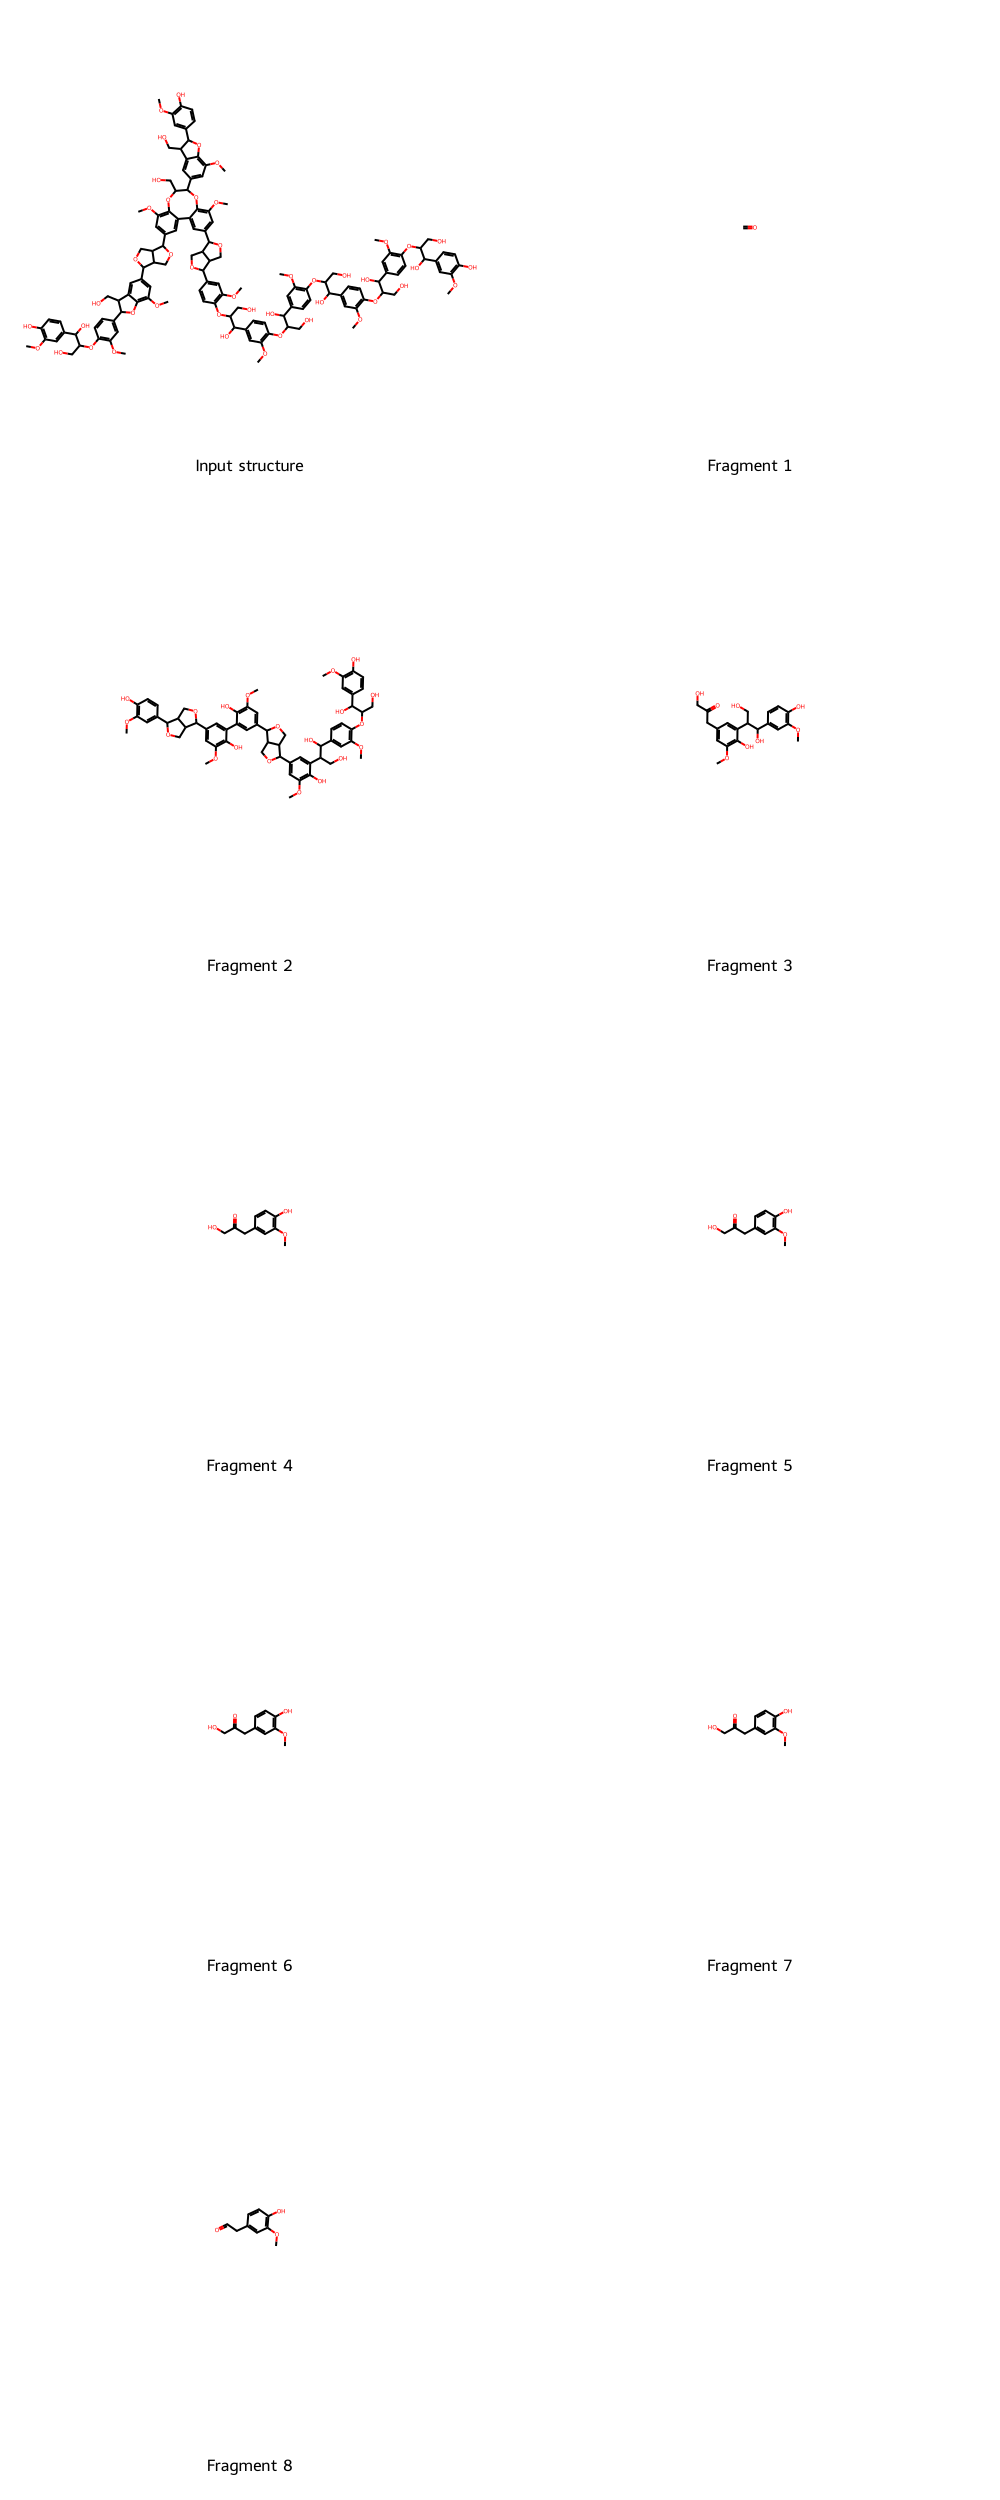

In [6]:
# Visualization: input vs. simulated fragments
frag_mols = [Chem.MolFromSmiles(f) for f in all_fragments]
Draw.MolsToGridImage([mol] + frag_mols, molsPerRow=2, subImgSize=(500, 500),
                     legends=["Input structure"] + [f"Fragment {i+1}" for i in range(len(frag_mols))])

In [7]:
C=O.COc1cc(C(O)C(CO)Oc2ccc(C(O)C(CO)c3cc(C4OCC5C(c6cc(OC)c(O)c(-c7cc(C8OCC9C(c%10ccc(O)c(OC)c%10)OCC89)cc(OC)c7O)c6)OCC45)cc(OC)c3O)cc2OC)ccc1O.COc1cc(C(O)C(CO)c2cc(CC(=O)CO)cc(OC)c2O)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC=O)ccc1O

SyntaxError: invalid decimal literal (844136591.py, line 1)

In [ ]:
C=O.COc1cc(C(O)C(CO)c2cc(C3OCC4C(c5cc(OC)c(O)c(-c6cc(C7OCC8C(c9ccc(O)c(OC)c9)OCC78)cc(OC)c6O)c5)OCC34)cc(OC)c2O)ccc1O.COc1cc(C(O)C(CO)c2cc(CC(=O)CO)cc(OC)c2O)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC(=O)CO)ccc1O.COc1cc(CC=O)ccc1O